# First results: weather and departures

Run **Prepare_Data.ipynb** with the full year first. Then run this notebook from top to bottom.

It answers: **how often were flights delayed or cancelled when a weather condition was reported at departure?**
Tables and charts are saved in the `results/` folder.

If you see `No module named 'matplotlib'`, run `python -m pip install matplotlib` in the terminal (with `.venv` active).

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project folder (the one that contains Prepare_Data.ipynb).
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "Prepare_Data.ipynb").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the FlightDelaysAndWeather folder.")

processed = ROOT / "data" / "processed"
data_file = processed / "flights_weather_2024_full_year.csv"
if not data_file.exists():
    others = sorted(processed.glob("flights_weather_2024_*.csv"))
    if not others:
        raise FileNotFoundError("No combined CSV yet. Run Prepare_Data.ipynb first.")
    data_file = others[-1]
    print("Full-year file not found, so using", data_file.name)

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

df = pd.read_csv(data_file, low_memory=False)
for col in ["weather_matched", "condition_codes_available"]:   # True/False columns; blank counts as False
    df[col] = df[col].astype(str).str.strip().str.lower().eq("true")
df["flight_date"] = pd.to_datetime(df["FlightDate"], errors="coerce")
df["month"] = df["flight_date"].dt.month
df["local_hour"] = pd.to_numeric(df["CRSDepTime"], errors="coerce") // 100
AIRPORT_ORDER = [a for a in ["BNA", "MEM", "TYS", "CHA"] if a in set(df["Origin"])]
print(f"Loaded {len(df):,} departures from {data_file.name}")

Loaded 145,978 departures from flights_weather_2024_full_year.csv


## 1. Data inventory
These are the numbers to report at the progress check: flights per airport, cancellations, how many flights matched a weather report, and how many matched reports had usable condition codes.

In [18]:
inventory = df.groupby("Origin").agg(
    flights=("flight_id", "size"),
    cancelled=("Cancelled", "sum"),
    matched_weather_pct=("weather_matched", "mean"),
    condition_codes_pct=("condition_codes_available", "mean"),
    median_weather_age_min=("weather_age_minutes", "median"),
).reindex(AIRPORT_ORDER)
inventory.loc["All"] = [len(df), df["Cancelled"].sum(), df["weather_matched"].mean(),
                        df["condition_codes_available"].mean(), df["weather_age_minutes"].median()]
inventory["flights"] = inventory["flights"].astype(int)
inventory["cancelled"] = inventory["cancelled"].astype(int)
for c in ["matched_weather_pct", "condition_codes_pct"]:
    inventory[c] = (100 * inventory[c]).round(1)
display(inventory)
inventory.to_csv(RESULTS / "data_inventory.csv")

,flights,cancelled,matched_weather_pct,condition_codes_pct,median_weather_age_min
Origin,,,,,
BNA,100220,1273,99.9,8.0,27.0
MEM,22624,306,99.7,9.1,22.0
TYS,16281,257,99.5,12.0,23.0
CHA,6853,85,99.8,10.3,23.0
All,145978,1921,99.8,8.8,27.0


## 2. Add threshold categories
The condition flags (rain, snow, fog, ...) come from Prepare_Data. Here we add three categories from the measured numbers:

- **IFR or worse:** ceiling below 305 m (1,000 ft) or visibility below 4,828 m (3 miles), the FAA's instrument flight rules threshold. A ceiling of 22,000 means "unlimited."
- **Strong wind:** sustained wind of 10.3 m/s (20 knots) or more. Gusts (OC1) are not decoded yet.
- **Heavy rain:** more than 7.6 mm in one hour (the National Weather Service's heavy-rain rate, 0.30 inch per hour).

Each column is 1 (yes), 0 (no), or blank (unknown). The coverage table shows how many flights fall in each group.

In [19]:
vis, ceiling = df["visibility_m"], df["ceiling_m"]
low = (vis < 4828) | (ceiling < 305)
df["ifr_or_worse"] = np.where(low, 1.0, np.where(vis.notna() & ceiling.notna(), 0.0, np.nan))

wind = df["wind_speed_mps"]
df["strong_wind"] = np.where(wind >= 10.3, 1.0, np.where(wind.notna(), 0.0, np.nan))

rain_mm = df["precipitation_1hr_mm"]
df["heavy_rain"] = np.where(rain_mm > 7.6, 1.0, np.where(rain_mm.notna(), 0.0, np.nan))

CONDITIONS = {
    "Thunderstorm": "thunderstorm_reported",
    "Snow": "snow_reported",
    "Freezing rain/drizzle": "freezing_precip_reported",
    "Ice pellets": "ice_pellets_reported",
    "Fog": "fog_reported",
    "Heavy rain (>7.6 mm/hr)": "heavy_rain",
    "Rain": "rain_reported",
    "Drizzle": "drizzle_reported",
    "Mist": "mist_reported",
    "IFR or worse": "ifr_or_worse",
    "Strong wind (20+ kt)": "strong_wind",
}
df["any_condition"] = df[list(CONDITIONS.values())].eq(1).any(axis=1)
# Comparison group: matched flights where none of the conditions above was reported.
# This is "nothing reported," not proof of clear weather.
df["no_condition"] = df["weather_matched"] & ~df["any_condition"]

coverage = pd.DataFrame({
    "reported (1)": [int(df[c].eq(1).sum()) for c in CONDITIONS.values()],
    "not reported (0)": [int(df[c].eq(0).sum()) for c in CONDITIONS.values()],
    "unknown (blank)": [int(df[c].isna().sum()) for c in CONDITIONS.values()],
}, index=list(CONDITIONS))
display(coverage)

,reported (1),not reported (0),unknown (blank)
Thunderstorm,1259,11536,133183
Snow,573,11417,133988
Freezing rain/drizzle,27,12765,133186
Ice pellets,17,12775,133186
Fog,668,12124,133186
Heavy rain (>7.6 mm/hr),282,128740,16956
Rain,8195,4507,133276
Drizzle,348,12436,133194
Mist,7259,5533,133186
IFR or worse,7122,138096,760


## 3. Delay and cancellation rates by weather
For each condition: the share of flights cancelled, and the share of flights that left 15+ minutes late (cancelled flights excluded).
The low/high columns are 95% confidence intervals.

In [20]:
def wilson(k, n, z=1.96):
    """95% Wilson confidence interval for the proportion k out of n."""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def rates(group):
    n = len(group)
    cancelled = int(group["Cancelled"].sum())
    flown = group["departure_delayed_15min"].dropna()
    delayed = int(flown.sum())
    c_low, c_high = wilson(cancelled, n)
    d_low, d_high = wilson(delayed, len(flown))
    return pd.Series({
        "flights": n,
        "cancel_%": 100 * cancelled / n if n else np.nan,
        "cancel_low": 100 * c_low, "cancel_high": 100 * c_high,
        "delay15_%": 100 * delayed / len(flown) if len(flown) else np.nan,
        "delay_low": 100 * d_low, "delay_high": 100 * d_high,
    })

rows = {"No condition reported": rates(df[df["no_condition"]])}
for label, col in CONDITIONS.items():
    rows[label] = rates(df[df[col].eq(1)])
by_condition = pd.DataFrame(rows).T
by_condition["flights"] = by_condition["flights"].astype(int)
display(by_condition.round(1))
by_condition.round(2).to_csv(RESULTS / "rates_by_condition.csv")

,flights,cancel_%,cancel_low,cancel_high,delay15_%,delay_low,delay_high
No condition reported,130411,1.1,1.0,1.2,18.7,18.5,18.9
Thunderstorm,1259,1.7,1.1,2.5,56.3,53.5,59.0
Snow,573,38.4,34.5,42.4,61.8,56.6,66.7
Freezing rain/drizzle,27,33.3,18.6,52.2,38.9,20.3,61.4
Ice pellets,17,29.4,13.3,53.1,41.7,19.3,68.0
Fog,668,6.3,4.7,8.4,18.7,15.8,21.9
Heavy rain (>7.6 mm/hr),282,3.5,1.9,6.4,53.7,47.7,59.5
Rain,8195,1.7,1.4,2.0,26.7,25.7,27.6
Drizzle,348,5.7,3.8,8.7,22.3,18.1,27.1
Mist,7259,3.8,3.4,4.2,22.2,21.3,23.2


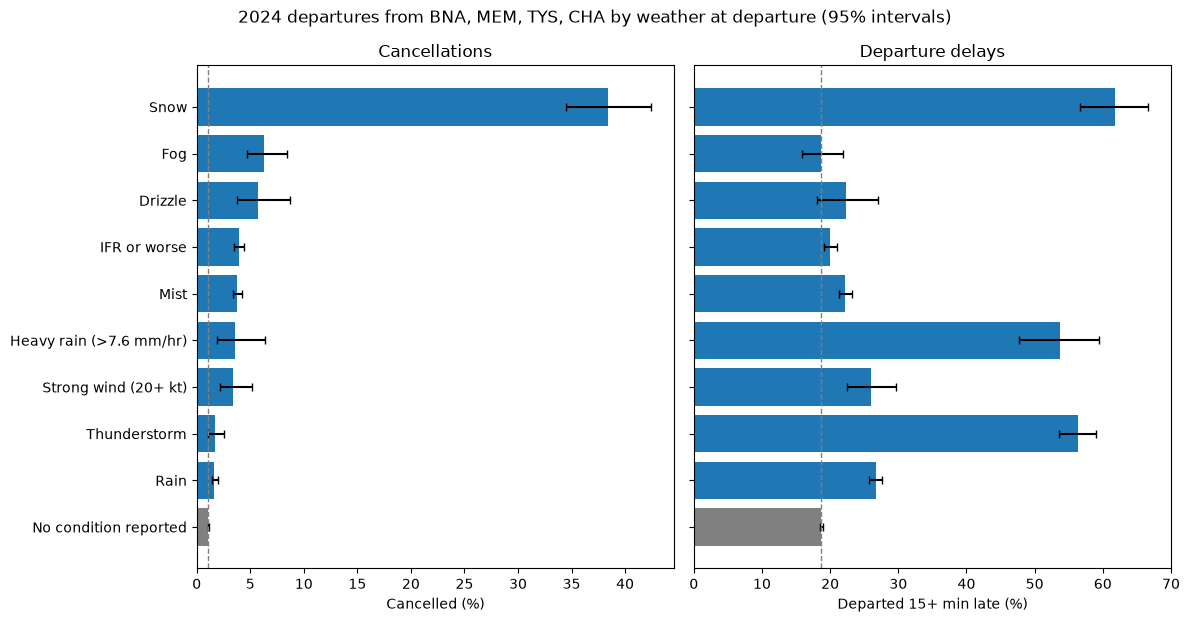

In [21]:
plot = by_condition[by_condition["flights"] >= 30].sort_values("cancel_%")
fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * len(plot) + 1.8), sharey=True)
panels = [("cancel_%", "cancel_low", "cancel_high", "Cancelled (%)"),
          ("delay15_%", "delay_low", "delay_high", "Departed 15+ min late (%)")]
for ax, (rate, low_col, high_col, label) in zip(axes, panels):
    errors = [plot[rate] - plot[low_col], plot[high_col] - plot[rate]]
    colors = ["grey" if name == "No condition reported" else "tab:blue" for name in plot.index]
    ax.barh(plot.index, plot[rate], xerr=errors, color=colors, capsize=3)
    ax.axvline(by_condition.loc["No condition reported", rate], color="grey", linestyle="--", linewidth=1)
    ax.set_xlabel(label)
axes[0].set_title("Cancellations")
axes[1].set_title("Departure delays")
fig.suptitle("2024 departures from BNA, MEM, TYS, CHA by weather at departure (95% intervals)")
fig.tight_layout()
fig.savefig(RESULTS / "rates_by_condition.png", dpi=150)
plt.show()

## 4. The same rates by airport
Check the flight counts before trusting a rate. Small groups (for example, snow at CHA) give wide, unreliable intervals.

In [22]:
airport_rows = []
for airport, g in df.groupby("Origin"):
    groups = [("No condition reported", g["no_condition"])]
    groups += [(label, g[col].eq(1)) for label, col in CONDITIONS.items()]
    for label, mask in groups:
        r = rates(g[mask])
        r["airport"], r["condition"] = airport, label
        airport_rows.append(r)
by_airport = pd.DataFrame(airport_rows)
order = ["No condition reported", *CONDITIONS]
cancel_table = by_airport.pivot(index="condition", columns="airport", values="cancel_%").reindex(order)[AIRPORT_ORDER]
count_table = by_airport.pivot(index="condition", columns="airport", values="flights").reindex(order)[AIRPORT_ORDER]
print("Cancelled (%) by airport:")
display(cancel_table.astype(float).round(1))
print("Number of flights in each group:")
display(count_table.astype(int))
by_airport.round(2).to_csv(RESULTS / "rates_by_airport.csv", index=False)

Cancelled (%) by airport:


airport,BNA,MEM,TYS,CHA
condition,,,,
No condition reported,1.0,1.3,1.3,1.1
Thunderstorm,1.7,1.1,2.4,0.0
Snow,39.2,38.4,33.3,33.3
Freezing rain/drizzle,NaN,0.0,81.8,NaN
Ice pellets,NaN,NaN,28.6,30.0
Fog,9.5,4.5,1.9,1.0
Heavy rain (>7.6 mm/hr),3.3,2.7,0.0,22.2
Rain,1.5,1.1,2.4,3.7
Drizzle,11.4,0.0,0.0,2.4


Number of flights in each group:


airport,BNA,MEM,TYS,CHA
condition,,,,
No condition reported,90425,19929,13948,6109
Thunderstorm,865,183,168,43
Snow,431,73,66,3
Freezing rain/drizzle,0,16,11,0
Ice pellets,0,0,7,10
Fog,391,22,159,96
Heavy rain (>7.6 mm/hr),215,37,21,9
Rain,5212,1403,1205,375
Drizzle,167,133,6,42


## 5. Checks against known events and BTS's own codes
**January 15, 2024 at BNA:** a snowstorm shut the airport down for part of the afternoon. The matched reports should show snow and IFR, along with many cancellations.

In [23]:
day = df[(df["Origin"] == "BNA") & (df["flight_date"] == pd.Timestamp("2024-01-15"))]
print(f"BNA on January 15, 2024: {len(day)} departures, {int(day['Cancelled'].sum())} cancelled")
hourly = day.groupby("local_hour").agg(
    flights=("flight_id", "size"),
    cancelled=("Cancelled", "sum"),
    snow_reported=("snow_reported", lambda s: int(s.eq(1).sum())),
    ifr_or_worse=("ifr_or_worse", lambda s: int(s.eq(1).sum())),
).astype(int)
hourly.index.name = "scheduled hour (local)"
display(hourly)

BNA on January 15, 2024: 256 departures, 175 cancelled


,flights,cancelled,snow_reported,ifr_or_worse
scheduled hour (local),,,,
5,9,4,9,1
6,21,11,21,10
7,15,8,15,15
8,22,13,22,22
9,13,9,13,13
10,23,13,23,23
11,9,5,9,9
12,13,7,13,13
13,13,8,13,13


**Cancellations by month and BTS cause:** look for weather cancellations (B) in January and a spike of carrier cancellations (A) in July, when the CrowdStrike IT outage grounded Delta flights. The second table checks whether BTS weather cancellations line up with weather we found at departure.

In [24]:
CAUSE = {"A": "Carrier", "B": "Weather", "C": "NAS", "D": "Security"}
cancelled = df[df["Cancelled"] == 1].copy()
cancelled["cause"] = cancelled["CancellationCode"].map(CAUSE).fillna("Unknown")
by_month = pd.crosstab(cancelled["month"], cancelled["cause"], margins=True, margins_name="Total")
display(by_month)
by_month.to_csv(RESULTS / "cancellations_by_month_and_cause.csv")

matched = cancelled[cancelled["weather_matched"]]
found = matched["any_condition"].map({True: "Condition reported at departure", False: "No condition reported"})
check = pd.crosstab(matched["cause"], found.rename("weather we matched"), normalize="index").mul(100).round(1)
print("Share of cancellations (%) by BTS cause and the weather we matched:")
display(check)
check.to_csv(RESULTS / "bts_cause_vs_matched_weather.csv")

cause,Carrier,NAS,Weather,Total
month,,,,
1,82,15,581,678
2,4,3,17,24
3,13,12,51,76
4,6,20,34,60
5,17,16,114,147
6,29,45,67,141
7,206,36,84,326
8,43,71,118,232
9,9,1,53,63


Share of cancellations (%) by BTS cause and the weather we matched:


weather we matched,Condition reported at departure,No condition reported
cause,,
Carrier,15.5,84.5
NAS,15.3,84.7
Weather,30.8,69.2


## Notes before presenting
- These are **associations, not causes**. Weather is from the departure airport only.
- Many flights in the same hour share one weather report, so the intervals are somewhat too narrow. The planned regression should handle this.
- A blank flag means unknown, not clear weather. Report the coverage table alongside the rates.
- Next: logistic regression (airline, hour, day of week, month, airport), wind gusts (OC1), a sensitivity check using weather up to 2 hours after departure, and the final write-up.